# 05 — Modélisation : prédire le prix de vente

On compare quatre approches, de la plus simple à la plus élaborée :

| # | Modèle | Idée |
|---|---|---|
| 0 | **Baseline** | prix au m² médian des 20 voisines × surface |
| 1 | **Régression linéaire** | une combinaison linéaire des variables |
| 2 | **Random Forest** | une moyenne de nombreux arbres de décision |
| 3 | **LightGBM** | des arbres construits les uns après les autres pour corriger les erreurs des précédents (*gradient boosting*) |

Tous les modèles prédisent le **log du prix** et sont évalués sur les **ventes de 2025**, qu'aucun d'eux n'a vues pendant l'entraînement.

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import lightgbm as lgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

racine = Path.cwd()
while not (racine / "data" / "raw").exists() and racine != racine.parent:
    racine = racine.parent

chemin = racine / "data" / "processed" / "features.parquet"
if not chemin.exists():
    raise FileNotFoundError(f"Fichier introuvable : {chemin}\n→ Lance d'abord le notebook 04_features jusqu'au bout.")

donnees = pd.read_parquet(chemin)
dossier_fig = racine / "figures"
dossier_modeles = racine / "models"
dossier_modeles.mkdir(exist_ok=True)

FEATURES = [
    "est_maison", "log_surface", "nombre_pieces_principales", "surface_par_piece", "log_terrain", "nb_dependances",
    "mois_depuis_2021", "mois",
    "latitude", "longitude", "dist_mer_km", "dist_grande_ville_km",
    "dist_marseille_km", "dist_nice_km", "dist_toulon_km", "dist_aix_km", "dist_avignon_km",
    "voisins_log_prix_m2", "voisins_distance_km",
]
CIBLE = "log_prix"

train = donnees[donnees["jeu"] == "train"]
test = donnees[donnees["jeu"] == "test"]
X_train, y_train = train[FEATURES], train[CIBLE]
X_test, y_test = test[FEATURES], test[CIBLE]
print(f"Entraînement : {len(train):,} ventes (2021-2024)")
print(f"Test         : {len(test):,} ventes (2025)")

Entraînement : 351,754 ventes (2021-2024)
Test         : 82,335 ventes (2025)


## Comment mesurer l'erreur ?

Le modèle prédit un log : on repasse en euros avec l'exponentielle, puis on compare au vrai prix avec des indicateurs compréhensibles par tout le monde :

- **Erreur médiane (%)** : la moitié des estimations se trompent de moins que ce pourcentage. C'est l'indicateur principal.
- **Erreur moyenne (%)** (*MAPE*) : plus sensible aux grosses erreurs.
- **Erreur médiane (€)** : l'écart typique en euros.
- **Part des estimations à ±10 % et à ±20 %** : est-ce que l'estimation est « dans la bonne fourchette » ?

In [2]:
def evaluer(nom, log_prediction, ventes=test):
    """Compare les prix prédits (en log) aux prix réels, en euros et en pourcentage."""
    prix_reel = ventes["valeur_fonciere"].to_numpy()
    prix_predit = np.exp(np.asarray(log_prediction))
    erreur_relative = np.abs(prix_predit - prix_reel) / prix_reel
    return {
        "Modèle": nom,
        "Erreur médiane (%)": np.median(erreur_relative) * 100,
        "Erreur moyenne (%)": np.mean(erreur_relative) * 100,
        "Erreur médiane (€)": np.median(np.abs(prix_predit - prix_reel)),
        "À ±10 % (%)": np.mean(erreur_relative <= 0.10) * 100,
        "À ±20 % (%)": np.mean(erreur_relative <= 0.20) * 100,
    }


resultats = []
predictions = {}

## 0. Baseline : le prix du quartier

Prix estimé = prix au m² médian des 20 voisines × surface. En log : `voisins_log_prix_m2 + log_surface`. Aucun apprentissage : c'est le point de référence.

In [3]:
predictions["Baseline (voisines)"] = test["voisins_log_prix_m2"] + test["log_surface"]
resultats.append(evaluer("Baseline (voisines)", predictions["Baseline (voisines)"]))
pd.DataFrame(resultats).round(1)

,Modèle,Erreur médiane (%),Erreur moyenne (%),Erreur médiane (€),À ±10 % (%),À ±20 % (%)
0,Baseline (voisines),16.9,24.9,36336.6,31.2,57.2


## 1. Régression linéaire

Le modèle le plus simple : le log du prix est une somme pondérée des variables. On **standardise** d'abord les variables (moyenne 0, écart-type 1) pour qu'elles soient sur la même échelle.

In [4]:
debut = time.time()
regression = make_pipeline(StandardScaler(), LinearRegression())
regression.fit(X_train, y_train)
predictions["Régression linéaire"] = regression.predict(X_test)
resultats.append(evaluer("Régression linéaire", predictions["Régression linéaire"]))
print(f"Entraîné en {time.time() - debut:.0f} s")
pd.DataFrame(resultats).round(1)

Entraîné en 3 s


,Modèle,Erreur médiane (%),Erreur moyenne (%),Erreur médiane (€),À ±10 % (%),À ±20 % (%)
0,Baseline (voisines),16.9,24.9,36336.6,31.2,57.2
1,Régression linéaire,15.8,25.3,34507.8,33.8,59.7


## 2. Random Forest

Une forêt de 100 arbres de décision, chacun entraîné sur un échantillon différent des données. La prédiction est la moyenne des arbres. Ce modèle capte les effets non linéaires et les interactions entre variables.

Pour limiter le temps de calcul et la mémoire, chaque arbre voit 50 % des ventes (`max_samples`) et une feuille contient au moins 10 ventes (`min_samples_leaf`).

In [5]:
debut = time.time()
foret = RandomForestRegressor(
    n_estimators=100, min_samples_leaf=10, max_features=0.5, max_samples=0.5,
    n_jobs=-1, random_state=42,
)
foret.fit(X_train, y_train)
predictions["Random Forest"] = foret.predict(X_test)
resultats.append(evaluer("Random Forest", predictions["Random Forest"]))
print(f"Entraîné en {time.time() - debut:.0f} s")
pd.DataFrame(resultats).round(1)

Entraîné en 80 s


,Modèle,Erreur médiane (%),Erreur moyenne (%),Erreur médiane (€),À ±10 % (%),À ±20 % (%)
0,Baseline (voisines),16.9,24.9,36336.6,31.2,57.2
1,Régression linéaire,15.8,25.3,34507.8,33.8,59.7
2,Random Forest,15.1,23.0,32618.4,34.9,62.1


## 3. LightGBM

Le *gradient boosting* construit les arbres **les uns après les autres**, chaque nouvel arbre corrigeant les erreurs des précédents. C'est souvent le modèle le plus performant sur les données tabulaires.

**Combien d'arbres ?** Trop peu, le modèle reste approximatif ; trop, il apprend le bruit des données d'entraînement (*surapprentissage*). Pour choisir **sans jamais regarder les données de test**, on procède en deux temps :

1. on entraîne sur 2021-2023 et on surveille l'erreur sur 2024 (**jeu de validation**) : on s'arrête quand elle ne baisse plus (*early stopping*) ;
2. on réentraîne sur toute la période 2021-2024 avec ce nombre d'arbres.

In [6]:
PARAMETRES = dict(
    learning_rate=0.05, num_leaves=127, min_child_samples=20,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    random_state=42, n_jobs=-1, verbose=-1,
)

est_validation = train["date_mutation"] >= "2024-01-01"
debut = time.time()
modele_validation = lgb.LGBMRegressor(n_estimators=5000, **PARAMETRES)
modele_validation.fit(
    X_train[~est_validation], y_train[~est_validation],
    eval_set=[(X_train[est_validation], y_train[est_validation])],
    callbacks=[lgb.early_stopping(100, verbose=False)],
)
nb_arbres = modele_validation.best_iteration_
print(f"Nombre d'arbres retenu : {nb_arbres} (trouvé en {time.time() - debut:.0f} s)")

Nombre d'arbres retenu : 1346 (trouvé en 36 s)


In [7]:
debut = time.time()
lightgbm = lgb.LGBMRegressor(n_estimators=nb_arbres, **PARAMETRES)
lightgbm.fit(X_train, y_train)
predictions["LightGBM"] = lightgbm.predict(X_test)
resultats.append(evaluer("LightGBM", predictions["LightGBM"]))
print(f"Entraîné en {time.time() - debut:.0f} s")

Entraîné en 35 s


## 4. Comparaison des modèles

In [8]:
tableau = pd.DataFrame(resultats).set_index("Modèle")
tableau.style.format({
    "Erreur médiane (%)": "{:.1f} %", "Erreur moyenne (%)": "{:.1f} %",
    "Erreur médiane (€)": "{:,.0f} €", "À ±10 % (%)": "{:.1f} %", "À ±20 % (%)": "{:.1f} %",
})

,Erreur médiane (%),Erreur moyenne (%),Erreur médiane (€),À ±10 % (%),À ±20 % (%)
Modèle,,,,,
Baseline (voisines),16.9 %,24.9 %,"36,337 €",31.2 %,57.2 %
Régression linéaire,15.8 %,25.3 %,"34,508 €",33.8 %,59.7 %
Random Forest,15.1 %,23.0 %,"32,618 €",34.9 %,62.1 %
LightGBM,14.9 %,22.7 %,"32,467 €",34.8 %,62.7 %


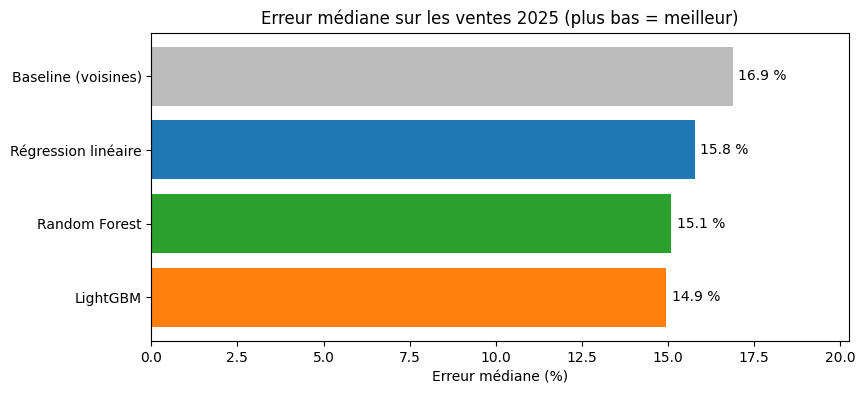

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
couleurs = ["#bbbbbb", "tab:blue", "tab:green", "tab:orange"]
barres = ax.barh(tableau.index[::-1], tableau["Erreur médiane (%)"][::-1], color=couleurs[::-1])
ax.bar_label(barres, fmt="%.1f %%", padding=4)
ax.set(title="Erreur médiane sur les ventes 2025 (plus bas = meilleur)", xlabel="Erreur médiane (%)")
ax.set_xlim(0, tableau["Erreur médiane (%)"].max() * 1.2)
fig.savefig(dossier_fig / "comparaison_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Le meilleur modèle en détail

Meilleur modèle : LightGBM


C:\Users\salwa\AppData\Local\Temp\ipykernel_6360\1639913798.py:15: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(dossier_fig / "predit_vs_reel.png", dpi=150, bbox_inches="tight")
c:\Users\salwa\estimateur-immo-dvf\.venv\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


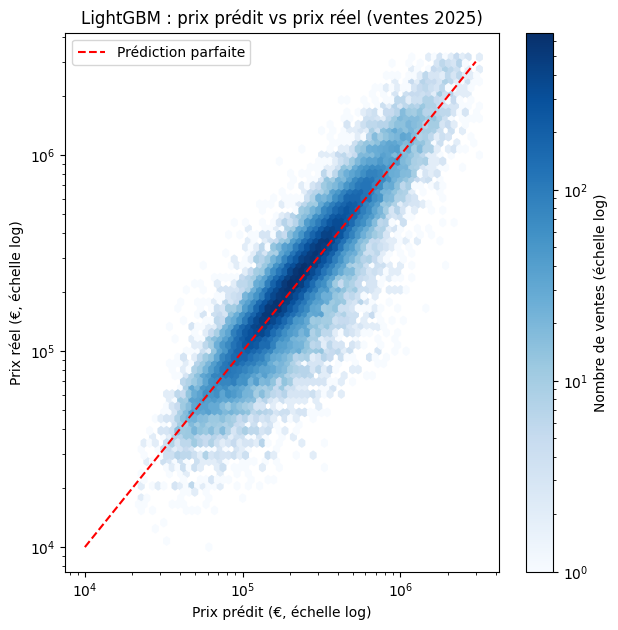

In [10]:
meilleur = tableau["Erreur médiane (%)"].idxmin()
print(f"Meilleur modèle : {meilleur}")

prix_predit = np.exp(predictions[meilleur])
prix_reel = test["valeur_fonciere"].to_numpy()

fig, ax = plt.subplots(figsize=(7, 7))
hb = ax.hexbin(prix_predit, prix_reel, gridsize=70, bins="log", cmap="Blues",
               xscale="log", yscale="log", extent=(4, 6.5, 4, 6.5))
ax.plot([1e4, 3e6], [1e4, 3e6], color="red", linestyle="--", label="Prédiction parfaite")
fig.colorbar(hb, ax=ax, label="Nombre de ventes (échelle log)")
ax.set(title=f"{meilleur} : prix prédit vs prix réel (ventes 2025)",
       xlabel="Prix prédit (€, échelle log)", ylabel="Prix réel (€, échelle log)")
ax.legend()
fig.savefig(dossier_fig / "predit_vs_reel.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Où le modèle se trompe-t-il ?

Un bon data scientist ne s'arrête pas à un score global : il regarde **pour quels biens** le modèle est fiable ou non.

In [11]:
analyse = test[["type_local", "code_departement", "nom_commune", "valeur_fonciere", "dist_mer_km"]].copy()
analyse["erreur_relative"] = np.abs(prix_predit - prix_reel) / prix_reel

NOMS_DEP = {"04": "Alpes-de-Haute-Provence", "05": "Hautes-Alpes", "06": "Alpes-Maritimes",
            "13": "Bouches-du-Rhône", "83": "Var", "84": "Vaucluse"}
analyse["departement"] = analyse["code_departement"].map(NOMS_DEP)
analyse["tranche_prix"] = pd.qcut(analyse["valeur_fonciere"], 5,
                                  labels=["20 % les moins chers", "2ᵉ quintile", "3ᵉ quintile", "4ᵉ quintile", "20 % les plus chers"])
analyse["zone"] = pd.cut(analyse["dist_mer_km"], [-1, 2, 10, 30, 1000],
                         labels=["Bord de mer (< 2 km)", "2 à 10 km", "10 à 30 km", "Plus de 30 km"])


def erreur_par(colonne):
    return (analyse.groupby(colonne, observed=True)["erreur_relative"]
            .agg(ventes="size", erreur_mediane=lambda e: np.median(e) * 100)
            .round(1))


erreur_par("type_local")

,ventes,erreur_mediane
type_local,,
Appartement,55318,14.2
Maison,27017,16.6


In [12]:
erreur_par("departement").sort_values("erreur_mediane")

,ventes,erreur_mediane
departement,,
Bouches-du-Rhône,25263,14.2
Var,21273,14.7
Alpes-Maritimes,23094,15.2
Vaucluse,6807,16.2
Hautes-Alpes,3032,17.1
Alpes-de-Haute-Provence,2866,17.8


In [13]:
erreur_par("zone")

,ventes,erreur_mediane
zone,,
Bord de mer (< 2 km),27544,15.1
2 à 10 km,23598,14.1
10 à 30 km,13217,14.3
Plus de 30 km,17976,16.7


In [14]:
erreur_par("tranche_prix")

,ventes,erreur_mediane
tranche_prix,,
20 % les moins chers,16468,18.2
2ᵉ quintile,16466,13.0
3ᵉ quintile,16779,13.0
4ᵉ quintile,16192,13.9
20 % les plus chers,16430,18.3


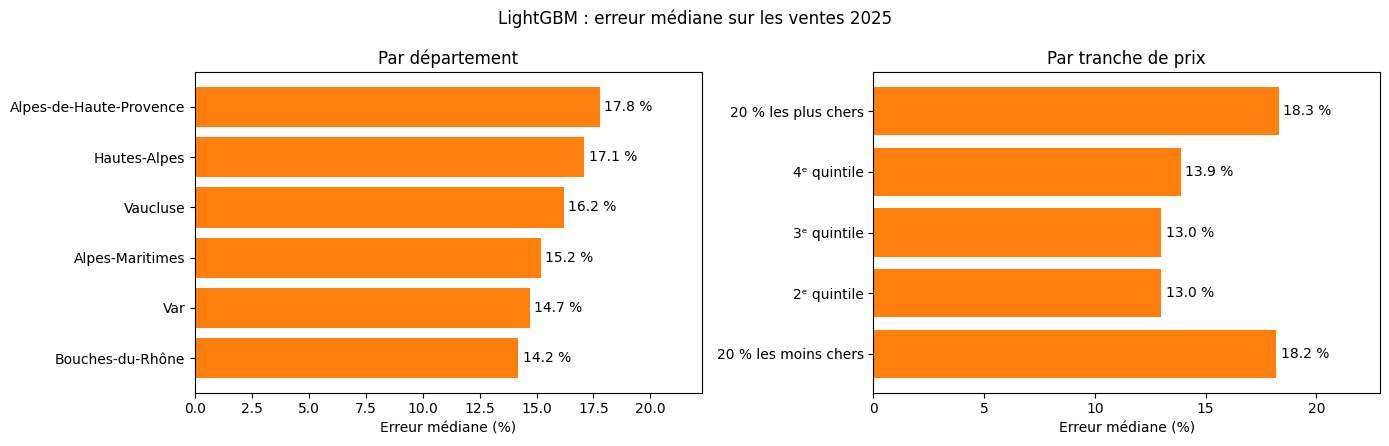

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, colonne, titre in [(axes[0], "departement", "Par département"), (axes[1], "tranche_prix", "Par tranche de prix")]:
    serie = erreur_par(colonne)["erreur_mediane"]
    if colonne == "departement":
        serie = serie.sort_values()
    barres = ax.barh(serie.index.astype(str), serie.values, color="tab:orange")
    ax.bar_label(barres, fmt="%.1f %%", padding=3)
    ax.set(title=titre, xlabel="Erreur médiane (%)")
    ax.set_xlim(0, serie.max() * 1.25)
fig.suptitle(f"{meilleur} : erreur médiane sur les ventes 2025")
fig.tight_layout()
fig.savefig(dossier_fig / "erreurs_par_segment.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Importance des variables

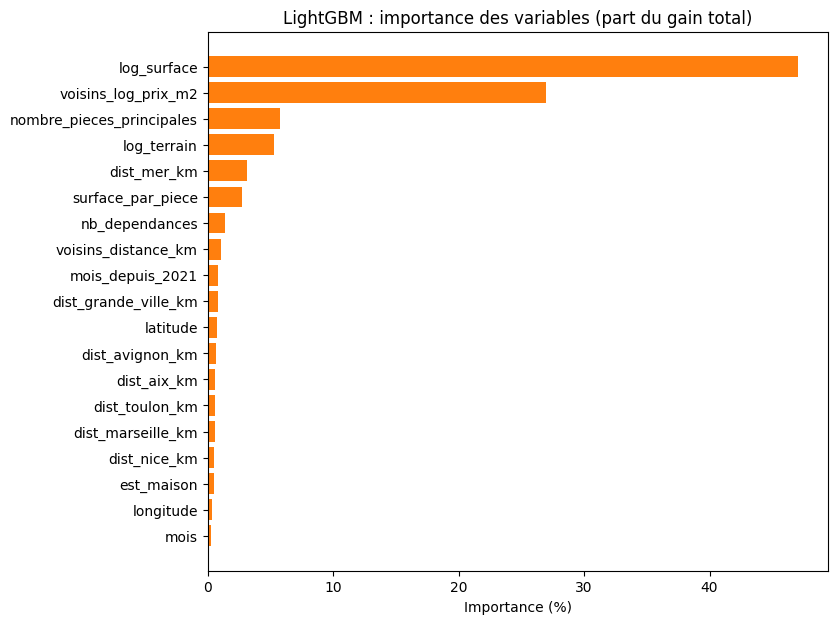

log_surface                  47.1
voisins_log_prix_m2          27.0
nombre_pieces_principales     5.7
log_terrain                   5.3
dist_mer_km                   3.2
surface_par_piece             2.7
nb_dependances                1.4
voisins_distance_km           1.0
mois_depuis_2021              0.9
dist_grande_ville_km          0.8
latitude                      0.7
dist_avignon_km               0.6
dist_aix_km                   0.6
dist_toulon_km                0.6
dist_marseille_km             0.6
dist_nice_km                  0.5
est_maison                    0.5
longitude                     0.4
mois                          0.2
dtype: float64

In [16]:
importance = pd.Series(lightgbm.booster_.feature_importance(importance_type="gain"), index=FEATURES)
importance = (importance / importance.sum() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(importance.index, importance.values, color="tab:orange")
ax.set(title="LightGBM : importance des variables (part du gain total)", xlabel="Importance (%)")
fig.savefig(dossier_fig / "importance_variables.png", dpi=150, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).round(1)

*L'importance « gain » mesure combien chaque variable a contribué à réduire l'erreur dans les arbres. Elle dit **quelles** variables comptent, mais pas **dans quel sens** elles jouent. Pour cela, on utilisera SHAP dans le notebook suivant.*

## 8. Sauvegarde du modèle

In [17]:
joblib.dump({"modele": lightgbm, "features": FEATURES}, dossier_modeles / "lightgbm.joblib")
print(f"Modèle sauvegardé dans {dossier_modeles / 'lightgbm.joblib'}")

Modèle sauvegardé dans c:\Users\salwa\estimateur-immo-dvf\models\lightgbm.joblib
